In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

c:\Users\daksh\anaconda3\envs\adaptive_gnn\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [3]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", DEVICE)

Using device: cpu


In [4]:
from pathlib import Path

PROJECT_DIR = Path("D:/adaptive_federated_gnn")

GRAPH_FILE = PROJECT_DIR / "data/processed/edge_graph.pt"

CLIENT_FILE = PROJECT_DIR / "outputs/day10/federated_clients.pt"

CONFIG_FILE = PROJECT_DIR / "outputs/day10/federated_config.pt"

OUTPUT_DIR = PROJECT_DIR / "outputs/day11"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Graph file:", GRAPH_FILE)
print("Client file:", CLIENT_FILE)
print("Output directory:", OUTPUT_DIR)

Graph file: D:\adaptive_federated_gnn\data\processed\edge_graph.pt
Client file: D:\adaptive_federated_gnn\outputs\day10\federated_clients.pt
Output directory: D:\adaptive_federated_gnn\outputs\day11


In [5]:
required_files = [
    GRAPH_FILE,
    CLIENT_FILE,
    CONFIG_FILE
]

for file_path in required_files:
    print(file_path)
    print("Exists:", file_path.exists())
    print("-" * 60)

D:\adaptive_federated_gnn\data\processed\edge_graph.pt
Exists: True
------------------------------------------------------------
D:\adaptive_federated_gnn\outputs\day10\federated_clients.pt
Exists: True
------------------------------------------------------------
D:\adaptive_federated_gnn\outputs\day10\federated_config.pt
Exists: True
------------------------------------------------------------


In [6]:
graph_data = torch.load(
    GRAPH_FILE,
    map_location=DEVICE,
    weights_only=False
)

print("Graph data loaded.")

print("Available keys:")
print(graph_data.keys())

Graph data loaded.
Available keys:
dict_keys(['edge_index', 'edge_attr', 'edge_label'])


In [7]:
federated_data = torch.load(
    CLIENT_FILE,
    map_location=DEVICE,
    weights_only=False
)

print("Federated client data loaded.")

print("Available keys:")
print(federated_data.keys())

Federated client data loaded.
Available keys:
dict_keys(['client_1', 'client_2', 'client_3'])


In [8]:
# Extract edge index
edge_index = graph_data["edge_index"].long().to(DEVICE)

# Calculate number of nodes
num_nodes = int(edge_index.max().item()) + 1

# Detect the correct edge feature key
if "edge_features" in graph_data:
    edge_feature_size = int(graph_data["edge_features"].shape[1])

elif "edge_attr" in graph_data:
    edge_feature_size = int(graph_data["edge_attr"].shape[1])

else:
    raise KeyError(
        f"No edge feature tensor found. Available keys: {list(graph_data.keys())}"
    )

print("Number of nodes:", num_nodes)
print("Number of graph edges:", edge_index.shape[1])
print("Edge feature size:", edge_feature_size)

Number of nodes: 4404
Number of graph edges: 286095
Edge feature size: 67


In [9]:
print(graph_data.keys())

dict_keys(['edge_index', 'edge_attr', 'edge_label'])


In [10]:
# Inspect and prepare federated client data

clients = torch.load(
    CLIENT_FILE,
    map_location="cpu",
    weights_only=False
)

print("Client names:", list(clients.keys()))

for client_name, client_data in clients.items():

    print("\nClient:", client_name)

    local_edge_indices = client_data["local_edge_indices"].long()

    client_edge_index = (
        client_data["edge_index"][:, local_edge_indices]
    )

    client_edge_features = client_data["edge_features"]
    client_edge_labels = client_data["edge_labels"]

    print("Client edge index shape:", client_edge_index.shape)
    print("Client edge features shape:", client_edge_features.shape)
    print("Client edge labels shape:", client_edge_labels.shape)

    assert client_edge_index.shape[1] == client_edge_features.shape[0]
    assert client_edge_features.shape[0] == client_edge_labels.shape[0]

print("\nAll client data prepared successfully.")

Client names: ['client_1', 'client_2', 'client_3']

Client: client_1
Client edge index shape: torch.Size([2, 66755])
Client edge features shape: torch.Size([66755, 67])
Client edge labels shape: torch.Size([66755])

Client: client_2
Client edge index shape: torch.Size([2, 66755])
Client edge features shape: torch.Size([66755, 67])
Client edge labels shape: torch.Size([66755])

Client: client_3
Client edge index shape: torch.Size([2, 66756])
Client edge features shape: torch.Size([66756, 67])
Client edge labels shape: torch.Size([66756])

All client data prepared successfully.


In [11]:
# Cell 10 — Prepare client-specific graph data

local_edge_indices = client_data["local_edge_indices"].long()

client_edge_index = (
    client_data["edge_index"][:, local_edge_indices]
)

client_edge_features = client_data["edge_features"].float()
client_edge_labels = client_data["edge_labels"].long()

In [12]:
# Cell 11 — Edge-level GCN model

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv


class EdgeGCN(nn.Module):

    def __init__(
        self,
        num_nodes,
        edge_feature_size,
        embedding_size=16,
        hidden_size=32
    ):
        super().__init__()

        self.node_embeddings = nn.Embedding(
            num_nodes,
            embedding_size
        )

        self.conv1 = GCNConv(
            embedding_size,
            hidden_size
        )

        self.conv2 = GCNConv(
            hidden_size,
            hidden_size
        )

        self.classifier = nn.Sequential(
            nn.Linear(
                hidden_size * 2 + edge_feature_size,
                64
            ),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, edge_index, edge_features):

        node_ids = torch.arange(
            self.node_embeddings.num_embeddings,
            device=edge_index.device
        )

        x = self.node_embeddings(node_ids)

        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        source_nodes = edge_index[0]
        destination_nodes = edge_index[1]

        source_embeddings = x[source_nodes]
        destination_embeddings = x[destination_nodes]

        combined_features = torch.cat(
            [
                source_embeddings,
                destination_embeddings,
                edge_features
            ],
            dim=1
        )

        return self.classifier(combined_features)


print("EdgeGCN model defined successfully.")

EdgeGCN model defined successfully.


In [13]:
# Cell 12 — Local training function

def train_local_model(
    model,
    edge_index,
    edge_features,
    edge_labels,
    epochs=10,
    learning_rate=0.001
):

    model = model.to(DEVICE)

    edge_index = edge_index.to(DEVICE)
    edge_features = edge_features.to(DEVICE)
    edge_labels = edge_labels.to(DEVICE)

    # Calculate class weights
    class_counts = torch.bincount(
        edge_labels,
        minlength=2
    ).float()

    class_weights = (
        class_counts.sum() /
        (2 * class_counts.clamp(min=1))
    )

    class_weights = class_weights.to(DEVICE)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = []

    model.train()

    for epoch in range(epochs):

        optimizer.zero_grad()

        outputs = model(
            edge_index,
            edge_features
        )

        loss = criterion(
            outputs,
            edge_labels
        )

        loss.backward()

        optimizer.step()

        history.append(loss.item())

        print(
            f"Epoch {epoch + 1:02d}/{epochs} "
            f"- Loss: {loss.item():.6f}"
        )

    return model, history

In [14]:
# Cell 13 — Evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


def evaluate_model(
    model,
    edge_index,
    edge_features,
    edge_labels
):

    model.eval()

    edge_index = edge_index.to(DEVICE)
    edge_features = edge_features.to(DEVICE)
    edge_labels = edge_labels.to(DEVICE)

    with torch.no_grad():

        outputs = model(
            edge_index,
            edge_features
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

    y_true = edge_labels.cpu().numpy()
    y_pred = predictions.cpu().numpy()

    attack_probability = (
        probabilities[:, 1]
        .cpu()
        .numpy()
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_true,
        attack_probability
    )

    pr_auc = average_precision_score(
        y_true,
        attack_probability
    )

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "confusion_matrix": cm
    }

In [15]:
# Cell 14 — Create Day 11 output directory

from pathlib import Path

DAY11_OUTPUT = Path(
    "D:/adaptive_federated_gnn/outputs/day11"
)

DAY11_OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory:", DAY11_OUTPUT)

Output directory: D:\adaptive_federated_gnn\outputs\day11


# client 1

In [16]:
# Cell 15 — Train client 1

client_name = "client_1"
client_data = clients[client_name]

local_edge_indices = (
    client_data["local_edge_indices"].long()
)

client_edge_index = (
    client_data["edge_index"][:, local_edge_indices]
)

client_edge_features = (
    client_data["edge_features"]
    .float()
)

client_edge_labels = (
    client_data["edge_labels"]
    .long()
)

print("Client:", client_name)
print("Edges:", client_edge_index.shape[1])
print("Features:", client_edge_features.shape)
print("Labels:", client_edge_labels.shape)

model = EdgeGCN(
    num_nodes=num_nodes,
    edge_feature_size=edge_feature_size
)

model, history = train_local_model(
    model,
    client_edge_index,
    client_edge_features,
    client_edge_labels,
    epochs=10
)

metrics = evaluate_model(
    model,
    client_edge_index,
    client_edge_features,
    client_edge_labels
)

print("\nClient 1 Results:")
print("Accuracy :", metrics["accuracy"])
print("Precision:", metrics["precision"])
print("Recall   :", metrics["recall"])
print("F1       :", metrics["f1"])
print("ROC-AUC  :", metrics["roc_auc"])
print("PR-AUC   :", metrics["pr_auc"])

torch.save(
    model.state_dict(),
    DAY11_OUTPUT / "client_1_model.pt"
)

print("\nClient 1 model saved.")

Client: client_1
Edges: 66755
Features: torch.Size([66755, 67])
Labels: torch.Size([66755])
Epoch 01/10 - Loss: 0.717763
Epoch 02/10 - Loss: 0.667702
Epoch 03/10 - Loss: 0.623325
Epoch 04/10 - Loss: 0.583634
Epoch 05/10 - Loss: 0.548143
Epoch 06/10 - Loss: 0.515711
Epoch 07/10 - Loss: 0.484568
Epoch 08/10 - Loss: 0.455790
Epoch 09/10 - Loss: 0.427011
Epoch 10/10 - Loss: 0.399210

Client 1 Results:
Accuracy : 0.9937982173619954
Precision: 0.9979072674892645
Recall   : 0.9909051654342311
F1       : 0.9943938901527462
ROC-AUC  : 0.998022713112293
PR-AUC   : 0.9968346597771464

Client 1 model saved.


# client 2

In [17]:
# Cell 16 — Train client 2

client_name = "client_2"
client_data = clients[client_name]

local_edge_indices = (
    client_data["local_edge_indices"].long()
)

client_edge_index = (
    client_data["edge_index"][:, local_edge_indices]
)

client_edge_features = (
    client_data["edge_features"]
    .float()
)

client_edge_labels = (
    client_data["edge_labels"]
    .long()
)

model = EdgeGCN(
    num_nodes=num_nodes,
    edge_feature_size=edge_feature_size
)

model, history = train_local_model(
    model,
    client_edge_index,
    client_edge_features,
    client_edge_labels,
    epochs=10
)

metrics = evaluate_model(
    model,
    client_edge_index,
    client_edge_features,
    client_edge_labels
)

print("\nClient 2 Results:")
print("Accuracy :", metrics["accuracy"])
print("Precision:", metrics["precision"])
print("Recall   :", metrics["recall"])
print("F1       :", metrics["f1"])
print("ROC-AUC  :", metrics["roc_auc"])
print("PR-AUC   :", metrics["pr_auc"])

torch.save(
    model.state_dict(),
    DAY11_OUTPUT / "client_2_model.pt"
)

print("\nClient 2 model saved.")

Epoch 01/10 - Loss: 0.727972
Epoch 02/10 - Loss: 0.679365
Epoch 03/10 - Loss: 0.633974
Epoch 04/10 - Loss: 0.594669
Epoch 05/10 - Loss: 0.559533
Epoch 06/10 - Loss: 0.524254
Epoch 07/10 - Loss: 0.493404
Epoch 08/10 - Loss: 0.462034
Epoch 09/10 - Loss: 0.432569
Epoch 10/10 - Loss: 0.403032

Client 2 Results:
Accuracy : 0.9955958355179387
Precision: 0.994724375538329
Recall   : 0.9973552113132186
F1       : 0.9960380562218688
ROC-AUC  : 0.9985345082882312
PR-AUC   : 0.9992868614918562

Client 2 model saved.


# client 3 

In [18]:
# Cell 17 — Train client 3

client_name = "client_3"
client_data = clients[client_name]

local_edge_indices = (
    client_data["local_edge_indices"].long()
)

client_edge_index = (
    client_data["edge_index"][:, local_edge_indices]
)

client_edge_features = (
    client_data["edge_features"]
    .float()
)

client_edge_labels = (
    client_data["edge_labels"]
    .long()
)

model = EdgeGCN(
    num_nodes=num_nodes,
    edge_feature_size=edge_feature_size
)

model, history = train_local_model(
    model,
    client_edge_index,
    client_edge_features,
    client_edge_labels,
    epochs=10
)

metrics = evaluate_model(
    model,
    client_edge_index,
    client_edge_features,
    client_edge_labels
)

print("\nClient 3 Results:")
print("Accuracy :", metrics["accuracy"])
print("Precision:", metrics["precision"])
print("Recall   :", metrics["recall"])
print("F1       :", metrics["f1"])
print("ROC-AUC  :", metrics["roc_auc"])
print("PR-AUC   :", metrics["pr_auc"])

torch.save(
    model.state_dict(),
    DAY11_OUTPUT / "client_3_model.pt"
)

print("\nClient 3 model saved.")

Epoch 01/10 - Loss: 0.704960
Epoch 02/10 - Loss: 0.666511
Epoch 03/10 - Loss: 0.629945
Epoch 04/10 - Loss: 0.597268
Epoch 05/10 - Loss: 0.565768
Epoch 06/10 - Loss: 0.536879
Epoch 07/10 - Loss: 0.509819
Epoch 08/10 - Loss: 0.484398
Epoch 09/10 - Loss: 0.460138
Epoch 10/10 - Loss: 0.435734

Client 3 Results:
Accuracy : 0.9954011624423272
Precision: 0.9975628249566725
Recall   : 0.9941438402374848
F1       : 0.9958503980644202
ROC-AUC  : 0.9983251069260162
PR-AUC   : 0.998196509513583

Client 3 model saved.


In [19]:
# Cell 18 — Train all three clients and collect results

import pandas as pd

all_results = []
all_histories = []

for client_name, client_data in clients.items():

    print("\n" + "=" * 60)
    print("Training:", client_name)
    print("=" * 60)

    local_edge_indices = (
        client_data["local_edge_indices"].long()
    )

    client_edge_index = (
        client_data["edge_index"][:, local_edge_indices]
    )

    client_edge_features = (
        client_data["edge_features"].float()
    )

    client_edge_labels = (
        client_data["edge_labels"].long()
    )

    # Safety checks
    assert (
        client_edge_index.shape[1]
        == client_edge_features.shape[0]
    )

    assert (
        client_edge_features.shape[0]
        == client_edge_labels.shape[0]
    )

    model = EdgeGCN(
        num_nodes=num_nodes,
        edge_feature_size=edge_feature_size
    )

    model, history = train_local_model(
        model,
        client_edge_index,
        client_edge_features,
        client_edge_labels,
        epochs=10
    )

    metrics = evaluate_model(
        model,
        client_edge_index,
        client_edge_features,
        client_edge_labels
    )

    all_results.append({
        "client": client_name,
        "edges": client_edge_features.shape[0],
        "accuracy": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
        "roc_auc": metrics["roc_auc"],
        "pr_auc": metrics["pr_auc"]
    })

    for epoch, loss in enumerate(history, start=1):

        all_histories.append({
            "client": client_name,
            "epoch": epoch,
            "loss": loss
        })

    torch.save(
        model.state_dict(),
        DAY11_OUTPUT / f"{client_name}_model.pt"
    )

results_df = pd.DataFrame(all_results)

history_df = pd.DataFrame(all_histories)

results_df.to_csv(
    DAY11_OUTPUT / "local_client_metrics.csv",
    index=False
)

history_df.to_csv(
    DAY11_OUTPUT / "local_training_history.csv",
    index=False
)

print("\nAll clients trained successfully.")

display(results_df)


Training: client_1
Epoch 01/10 - Loss: 0.807569
Epoch 02/10 - Loss: 0.745224
Epoch 03/10 - Loss: 0.691106
Epoch 04/10 - Loss: 0.643077
Epoch 05/10 - Loss: 0.599265
Epoch 06/10 - Loss: 0.560466
Epoch 07/10 - Loss: 0.523121
Epoch 08/10 - Loss: 0.488775
Epoch 09/10 - Loss: 0.455402
Epoch 10/10 - Loss: 0.424354

Training: client_2
Epoch 01/10 - Loss: 0.642776
Epoch 02/10 - Loss: 0.595388
Epoch 03/10 - Loss: 0.553424
Epoch 04/10 - Loss: 0.513181
Epoch 05/10 - Loss: 0.476104
Epoch 06/10 - Loss: 0.440530
Epoch 07/10 - Loss: 0.407766
Epoch 08/10 - Loss: 0.375932
Epoch 09/10 - Loss: 0.345194
Epoch 10/10 - Loss: 0.316393

Training: client_3
Epoch 01/10 - Loss: 0.746557
Epoch 02/10 - Loss: 0.693975
Epoch 03/10 - Loss: 0.647456
Epoch 04/10 - Loss: 0.604534
Epoch 05/10 - Loss: 0.564733
Epoch 06/10 - Loss: 0.529758
Epoch 07/10 - Loss: 0.497767
Epoch 08/10 - Loss: 0.467249
Epoch 09/10 - Loss: 0.438014
Epoch 10/10 - Loss: 0.409885

All clients trained successfully.


,client,edges,accuracy,precision,recall,f1,roc_auc,pr_auc
0,client_1,66755,0.996300,0.995477,0.997868,0.996671,0.998587,0.999318
1,client_2,66755,0.998547,0.999540,0.997841,0.998690,0.998848,0.999315
2,client_3,66756,0.994038,0.995004,0.994252,0.994628,0.998120,0.998688


In [20]:
# Cell 19 — Save confusion matrices

confusion_results = []

for client_name, client_data in clients.items():

    local_edge_indices = (
        client_data["local_edge_indices"].long()
    )

    client_edge_index = (
        client_data["edge_index"][:, local_edge_indices]
    )

    client_edge_features = (
        client_data["edge_features"].float()
    )

    client_edge_labels = (
        client_data["edge_labels"].long()
    )

    model = EdgeGCN(
        num_nodes=num_nodes,
        edge_feature_size=edge_feature_size
    )

    model.load_state_dict(
        torch.load(
            DAY11_OUTPUT / f"{client_name}_model.pt",
            map_location=DEVICE,
            weights_only=True
        )
    )

    metrics = evaluate_model(
        model,
        client_edge_index,
        client_edge_features,
        client_edge_labels
    )

    cm = metrics["confusion_matrix"]

    confusion_results.append({
        "client": client_name,
        "TN": int(cm[0, 0]),
        "FP": int(cm[0, 1]),
        "FN": int(cm[1, 0]),
        "TP": int(cm[1, 1])
    })

confusion_df = pd.DataFrame(
    confusion_results
)

confusion_df.to_csv(
    DAY11_OUTPUT / "local_confusion_matrices.csv",
    index=False
)

display(confusion_df)

,client,TN,FP,FN,TP
0,client_1,29533,168,79,36975
1,client_2,29684,17,80,36974
2,client_3,29516,185,213,36842


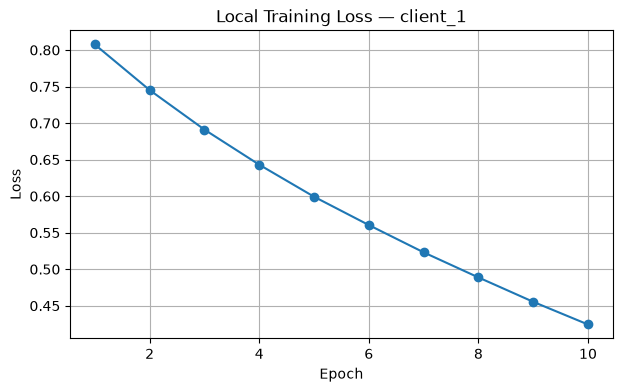

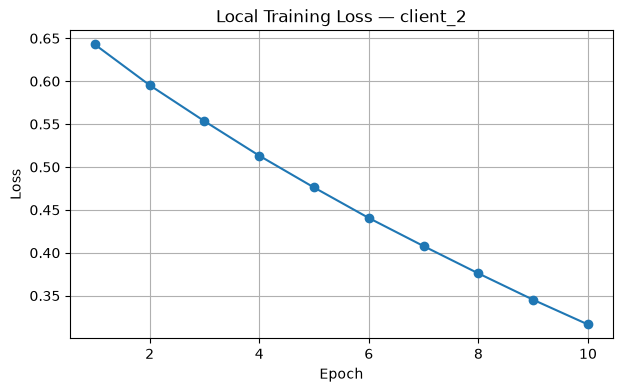

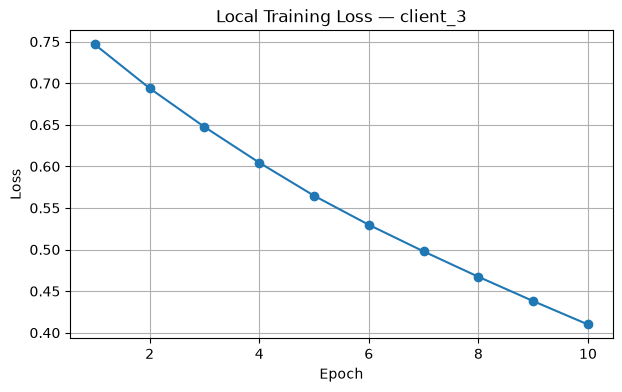

In [21]:
# Cell 20 — Plot local training loss

import matplotlib.pyplot as plt

for client_name in history_df["client"].unique():

    client_history = history_df[
        history_df["client"] == client_name
    ]

    plt.figure(figsize=(7, 4))

    plt.plot(
        client_history["epoch"],
        client_history["loss"],
        marker="o"
    )

    plt.title(
        f"Local Training Loss — {client_name}"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.grid(True)

    plt.show()

In [23]:
# Cell 21 — Day 11 completion check

print("DAY 11 OUTPUTS")
print("=" * 50)

for file_name in [
    "client_1_model.pt",
    "client_2_model.pt",
    "client_3_model.pt",
    "local_client_metrics.csv",
    "local_training_history.csv",
    "local_confusion_matrices.csv"
]:

    file_path = DAY11_OUTPUT / file_name

    print(
        f"{file_name}:",
        "P" if file_path.exists() else "A"
    )

print("\nClient metrics:")
display(results_df)

DAY 11 OUTPUTS
client_1_model.pt: P
client_2_model.pt: P
client_3_model.pt: P
local_client_metrics.csv: P
local_training_history.csv: P
local_confusion_matrices.csv: P

Client metrics:


,client,edges,accuracy,precision,recall,f1,roc_auc,pr_auc
0,client_1,66755,0.996300,0.995477,0.997868,0.996671,0.998587,0.999318
1,client_2,66755,0.998547,0.999540,0.997841,0.998690,0.998848,0.999315
2,client_3,66756,0.994038,0.995004,0.994252,0.994628,0.998120,0.998688
